In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Load cleaned dataset
df_clean = pd.read_csv("online_retail_day1_cleaned.csv")

# Convert data types
df_clean["InvoiceDate"] = pd.to_datetime(df_clean["InvoiceDate"])
df_clean["CustomerID"] = df_clean["CustomerID"].astype(int)

# Set reference date
reference_date = df_clean["InvoiceDate"].max() + pd.Timedelta(days=1)

# Rebuild RFM table
rfm = df_clean.groupby("CustomerID").agg({
    "InvoiceDate": lambda x: (reference_date - x.max()).days,
    "InvoiceNo": "nunique",
    "TotalAmount": "sum"
})

rfm.rename(columns={
    "InvoiceDate": "Recency",
    "InvoiceNo": "Frequency",
    "TotalAmount": "Monetary"
}, inplace=True)

# Log transformation
rfm_log = np.log1p(rfm)

# Feature scaling
scaler = StandardScaler()
rfm_scaled = pd.DataFrame(
    scaler.fit_transform(rfm_log),
    columns=["Recency", "Frequency", "Monetary"],
    index=rfm.index
)

print("RFM data restored successfully!")
print("RFM Shape:", rfm.shape)
print("Scaled RFM Shape:", rfm_scaled.shape)

RFM data restored successfully!
RFM Shape: (4338, 3)
Scaled RFM Shape: (4338, 3)


In [3]:
inertia_values = []
silhouette_values = []

K = range(2, 11)

for k in K:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(rfm_scaled)

    inertia_values.append(kmeans.inertia_)
    silhouette_values.append(
        silhouette_score(rfm_scaled, labels)
    )

print("Cluster evaluation completed!")

Cluster evaluation completed!


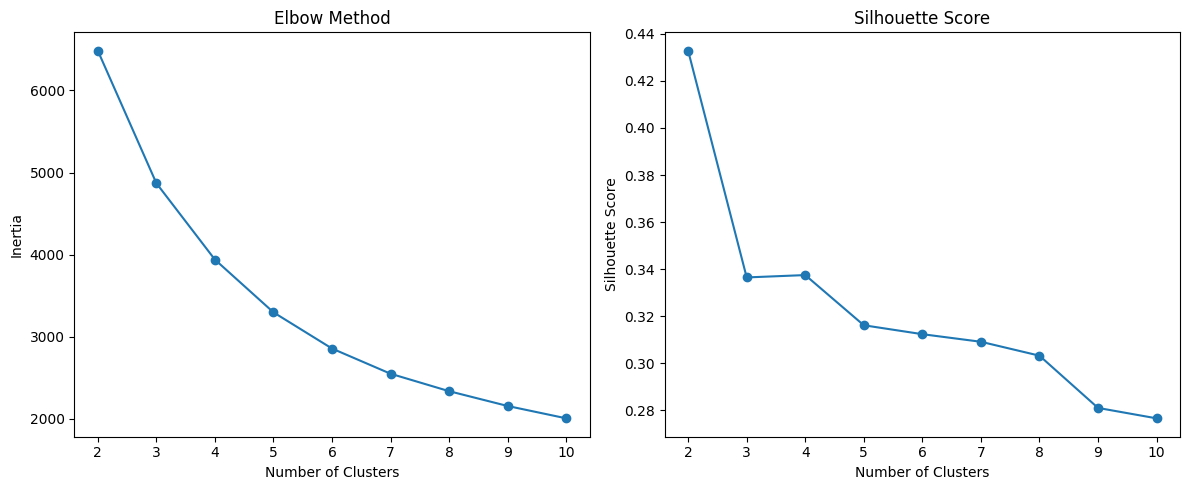

In [4]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(K, inertia_values, marker="o")
plt.title("Elbow Method")
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")

plt.subplot(1, 2, 2)
plt.plot(K, silhouette_values, marker="o")
plt.title("Silhouette Score")
plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")

plt.tight_layout()
plt.show()

In [5]:
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

rfm["Cluster"] = kmeans.fit_predict(rfm_scaled)

print("K-Means model trained successfully!")
print("\nCustomer distribution:")
print(rfm["Cluster"].value_counts().sort_index())

K-Means model trained successfully!

Customer distribution:
Cluster
0     713
1    1622
2     837
3    1166
Name: count, dtype: int64


In [6]:
cluster_summary = rfm.groupby("Cluster").agg({
    "Recency": "mean",
    "Frequency": "mean",
    "Monetary": "mean"
}).round(2)

cluster_summary

,Recency,Frequency,Monetary
Cluster,,,
0,12.17,13.75,8088.02
1,181.51,1.32,341.00
2,17.70,2.19,557.32
3,71.64,4.08,1801.78


In [7]:
cluster_counts = rfm["Cluster"].value_counts().sort_index()

cluster_percentage = (
    rfm["Cluster"].value_counts(normalize=True).sort_index() * 100
)

cluster_distribution = pd.DataFrame({
    "Number_of_Customers": cluster_counts,
    "Percentage": cluster_percentage.round(2)
})

cluster_distribution

,Number_of_Customers,Percentage
Cluster,,
0,713,16.44
1,1622,37.39
2,837,19.29
3,1166,26.88


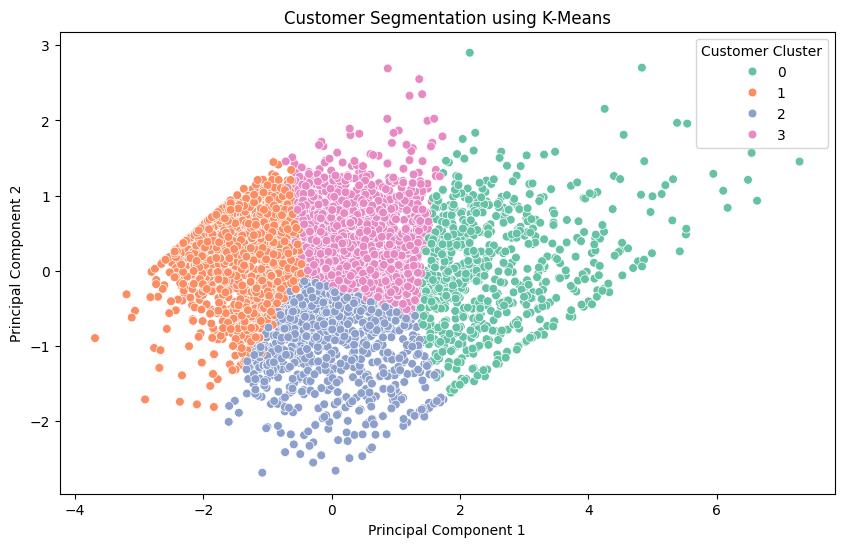

In [8]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)

rfm_pca = pca.fit_transform(rfm_scaled)

pca_df = pd.DataFrame({
    "PCA1": rfm_pca[:, 0],
    "PCA2": rfm_pca[:, 1],
    "Cluster": rfm["Cluster"].values
})

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=pca_df,
    x="PCA1",
    y="PCA2",
    hue="Cluster",
    palette="Set2",
    s=40
)

plt.title("Customer Segmentation using K-Means")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Customer Cluster")
plt.show()

In [9]:
rfm.to_csv("customer_segmentation_results.csv")

print("Customer segmentation results saved successfully!")

Customer segmentation results saved successfully!


In [12]:
segment_profiles = rfm.groupby("Cluster").agg(
    Customers=("Recency", "count"),
    Avg_Recency=("Recency", "mean"),
    Avg_Frequency=("Frequency", "mean"),
    Avg_Monetary=("Monetary", "mean")
).round(2)

segment_profiles

,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary
Cluster,,,,
0,713,12.17,13.75,8088.02
1,1622,181.51,1.32,341.00
2,837,17.70,2.19,557.32
3,1166,71.64,4.08,1801.78


In [13]:
segment_names = {
    0: "Champions",
    1: "At-Risk Customers",
    2: "Recent Occasional Buyers",
    3: "Regular Customers"
}

rfm["Segment"] = rfm["Cluster"].map(segment_names)

print("Customer segment names assigned successfully!")

rfm[["Recency", "Frequency", "Monetary", "Cluster", "Segment"]].head(10)

Customer segment names assigned successfully!


,Recency,Frequency,Monetary,Cluster,Segment
CustomerID,,,,,
12346,326,1,77183.60,3,Regular Customers
12347,2,7,4310.00,0,Champions
12348,75,4,1797.24,3,Regular Customers
12349,19,1,1757.55,2,Recent Occasional Buyers
12350,310,1,334.40,1,At-Risk Customers
12352,36,8,2506.04,3,Regular Customers
12353,204,1,89.00,1,At-Risk Customers
12354,232,1,1079.40,1,At-Risk Customers
12355,214,1,459.40,1,At-Risk Customers


In [15]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

inertia_values = []
silhouette_values = []

K = range(2, 11)

for k in K:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(rfm_scaled)

    inertia_values.append(model.inertia_)
    silhouette_values.append(
        silhouette_score(rfm_scaled, labels)
    )

print("Cluster evaluation completed!")

Cluster evaluation completed!


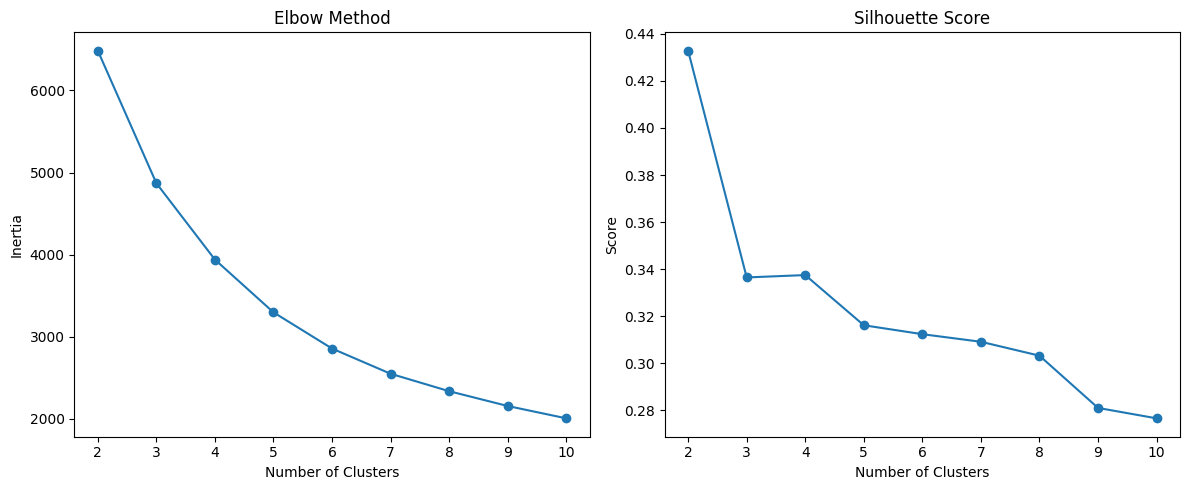

In [16]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(K, inertia_values, marker="o")
plt.title("Elbow Method")
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")

plt.subplot(1, 2, 2)
plt.plot(K, silhouette_values, marker="o")
plt.title("Silhouette Score")
plt.xlabel("Number of Clusters")
plt.ylabel("Score")

plt.tight_layout()
plt.show()